# Task 4 — House Price Analysis & Prediction

QSkill Internship | Domain: Data Science | Slab 1: Beginners

## 1. Objective
Analyze housing features and build regression models to estimate house prices. The notebook uses a reproducible synthetic housing dataset so it runs without downloading data. If the internship specifically requires a real dataset, replace the generated data with a permitted housing CSV.

In [7]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
n = 1000
area = rng.normal(1600, 500, n).clip(450, 4200)
bedrooms = rng.integers(1, 7, n)
bathrooms = rng.choice([1,1.5,2,2.5,3,3.5,4], n, p=[.12,.10,.25,.10,.22,.08,.13])
age = rng.integers(0, 80, n)
location = rng.choice(["Suburban","Urban","Rural"], n, p=[.48,.35,.17])
parking = rng.choice(["Yes","No"], n, p=[.72,.28])
location_effect = pd.Series(location).map({"Rural":-25000,"Suburban":15000,"Urban":45000}).to_numpy()
parking_effect = (parking=="Yes")*12000
price = 45000 + area*155 + bedrooms*8500 + bathrooms*11000 - age*900 + location_effect + parking_effect + rng.normal(0,35000,n)
housing = pd.DataFrame({"Area_sqft":area.round(0),"Bedrooms":bedrooms,"Bathrooms":bathrooms,
                        "Age_Years":age,"Location":location,"Parking":parking,"Price":price.clip(30000).round(0)})
housing.loc[10,"Area_sqft"] = np.nan
housing.loc[25,"Location"] = None
housing = pd.concat([housing, housing.iloc[[5]]], ignore_index=True)
housing.head()

,Area_sqft,Bedrooms,Bathrooms,Age_Years,Location,Parking,Price
0,1752.0,2,2.5,72,Urban,Yes,395204.0
1,1080.0,4,3.0,46,Urban,Yes,298582.0
2,1975.0,3,3.0,13,Suburban,No,352442.0
3,2070.0,3,3.5,62,Suburban,Yes,399297.0
4,624.0,5,2.0,11,Urban,No,251237.0


## 2. Data cleaning and outlier inspection

Shape before cleaning: (1001, 7)
Missing values:
 Area_sqft    1
Bedrooms     0
Bathrooms    0
Age_Years    0
Location     1
Parking      0
Price        0
dtype: int64
Duplicate rows: 1


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Area_sqft,1000.0,NaN,NaN,NaN,1587.186,488.858417,450.0,1251.75,1603.0,1894.25,3189.0
Bedrooms,1000.0,NaN,NaN,NaN,3.489,1.707863,1.0,2.0,3.0,5.0,6.0
Bathrooms,1000.0,NaN,NaN,NaN,2.4805,0.928295,1.0,2.0,2.5,3.0,4.0
Age_Years,1000.0,NaN,NaN,NaN,39.115,22.424153,0.0,19.75,39.0,59.0,79.0
Location,1000,3,Suburban,485,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Parking,1000,2,Yes,741,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,1000.0,NaN,NaN,NaN,342636.741,89827.308455,46343.0,280356.25,345176.0,402567.25,643355.0


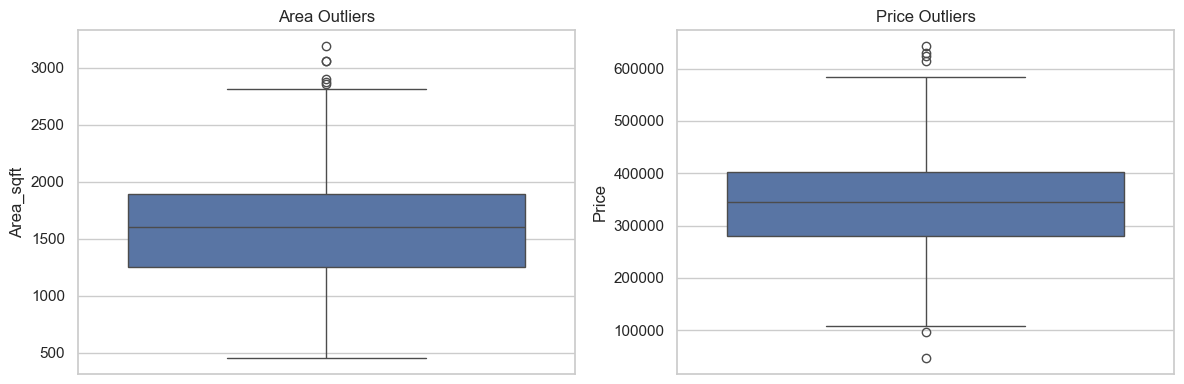

In [9]:
print("Shape before cleaning:", housing.shape)
print("Missing values:\n", housing.isna().sum())
print("Duplicate rows:", housing.duplicated().sum())
housing = housing.drop_duplicates().copy()
for col in ["Area_sqft","Bedrooms","Bathrooms","Age_Years","Price"]:
    housing[col] = pd.to_numeric(housing[col], errors="coerce")
housing["Area_sqft"] = housing["Area_sqft"].fillna(housing["Area_sqft"].median())
housing["Location"] = housing["Location"].fillna(housing["Location"].mode()[0])
housing = housing.dropna(subset=["Price"])
housing = housing[(housing["Area_sqft"] > 0) & (housing["Price"] > 0)]
display(housing.describe(include="all").T)
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.boxplot(y=housing["Area_sqft"], ax=axes[0]); axes[0].set_title("Area Outliers")
sns.boxplot(y=housing["Price"], ax=axes[1]); axes[1].set_title("Price Outliers")
plt.tight_layout()
plt.show()

## 3. Exploratory data analysis

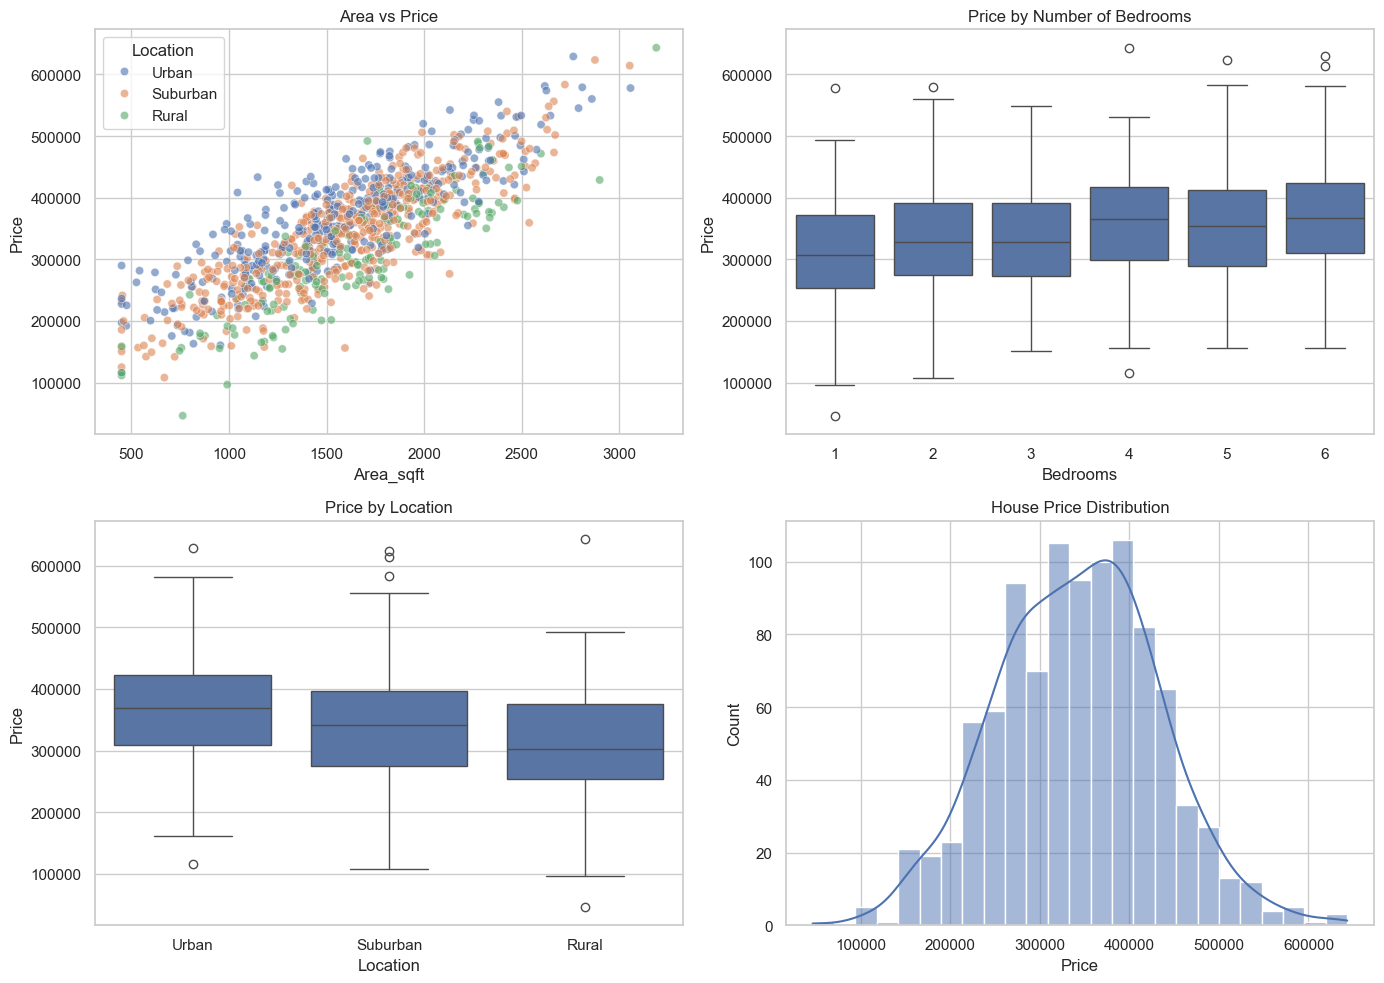

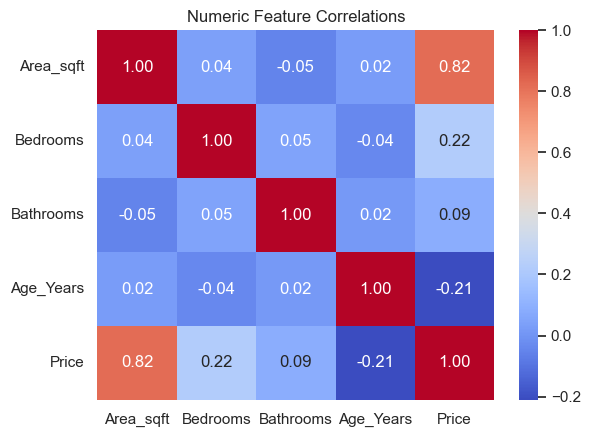

In [10]:
fig, axes = plt.subplots(2,2,figsize=(14,10))
sns.scatterplot(data=housing, x="Area_sqft", y="Price", hue="Location", alpha=.6, ax=axes[0,0])
axes[0,0].set_title("Area vs Price")
sns.boxplot(data=housing, x="Bedrooms", y="Price", ax=axes[0,1])
axes[0,1].set_title("Price by Number of Bedrooms")
sns.boxplot(data=housing, x="Location", y="Price", ax=axes[1,0])
axes[1,0].set_title("Price by Location")
sns.histplot(housing["Price"], kde=True, ax=axes[1,1])
axes[1,1].set_title("House Price Distribution")
plt.tight_layout()
plt.show()
sns.heatmap(housing.select_dtypes(include=np.number).corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Numeric Feature Correlations")
plt.show()

## 4. Preprocessing and regression model comparison

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = housing.drop(columns="Price")
y = housing["Price"]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), numeric_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features)
])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.2, random_state=RANDOM_STATE)
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=180, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE)
}
results, fitted = [], {}
for name, model in models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    results.append({"Model":name, "MAE":mean_absolute_error(y_test,pred),
                    "RMSE":mean_squared_error(y_test,pred)**0.5, "R2":r2_score(y_test,pred)})
    fitted[name] = pipe
results_df = pd.DataFrame(results).sort_values("RMSE")
display(results_df.round(2))

,Model,MAE,RMSE,R2
1,Ridge Regression,28791.17,37502.89,0.79
0,Linear Regression,28819.41,37528.90,0.79
3,Gradient Boosting,29828.58,39048.23,0.77
2,Random Forest,31543.15,41972.30,0.74


## 5. Prediction diagnostics and feature importance

Best model by RMSE: Ridge Regression


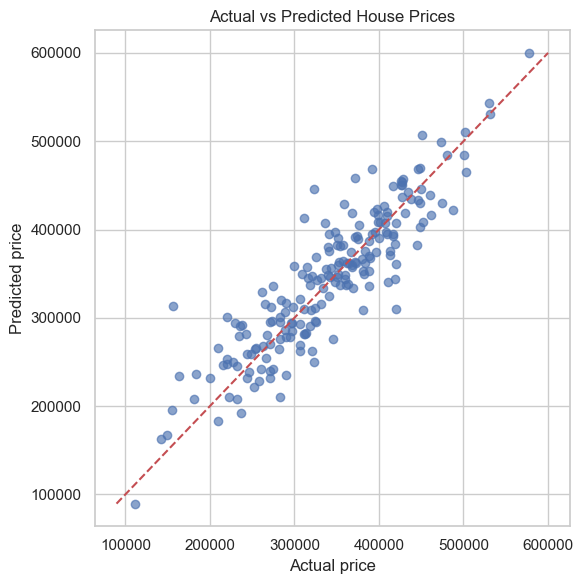

,Permutation Importance
Area_sqft,61657.756306
Location,10710.980361
Age_Years,8630.378033
Bedrooms,5682.921818
Bathrooms,1197.842397
Parking,816.962683


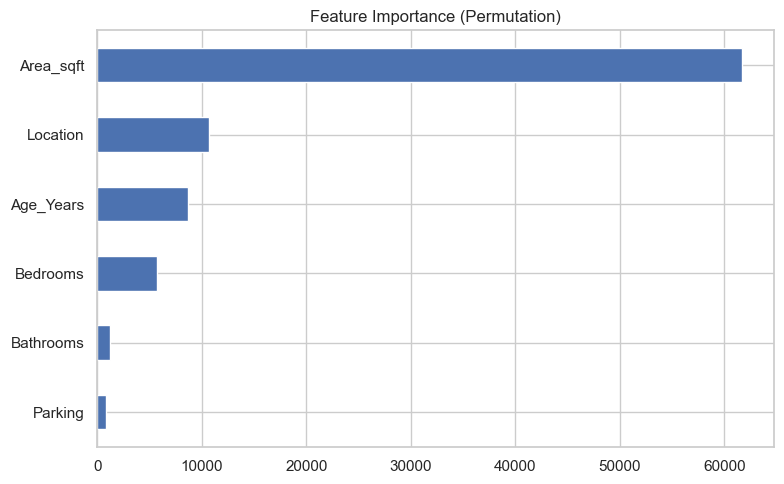

Interpretation: MAE is the average absolute error in price units; RMSE penalizes large errors more; R² measures explained variation (1 is best, 0 is similar to predicting the mean, and negative can be worse).
Conclusion: use the result table and feature-importance chart to report which model performed best and which features were most useful. This synthetic dataset demonstrates workflow, not real market prices.


In [12]:
best_name = results_df.iloc[0]["Model"]
best_model = fitted[best_name]
pred = best_model.predict(X_test)
print("Best model by RMSE:", best_name)
plt.figure(figsize=(6,6))
plt.scatter(y_test, pred, alpha=.65)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--")
plt.xlabel("Actual price"); plt.ylabel("Predicted price")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()
from sklearn.inspection import permutation_importance
perm = permutation_importance(best_model, X_test, y_test, n_repeats=8, random_state=RANDOM_STATE, scoring="neg_mean_absolute_error")
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
display(importance.sort_values(ascending=False).to_frame("Permutation Importance"))
importance.plot(kind="barh", figsize=(8,5), title="Feature Importance (Permutation)")
plt.tight_layout()
plt.show()
print("Interpretation: MAE is the average absolute error in price units; RMSE penalizes large errors more; R² measures explained variation (1 is best, 0 is similar to predicting the mean, and negative can be worse).")
print("Conclusion: use the result table and feature-importance chart to report which model performed best and which features were most useful. This synthetic dataset demonstrates workflow, not real market prices.")